# Regional Momentum on the MSCI ACWI

**2270 Financial Modeling, Group Assignment**

- Moodle group: BT
- Members: Renke Löschen (82016), Matti Raether (81317), Ben Bormann (78448), Felix Donder (75246),
  Leopold Querfurth (78371), Clara Liehr (80350)
- Streamlit app: *TODO (not yet deployed)*
- GitHub repository: https://github.com/donderfelix-spec/fm_group

## Setup
Open this notebook in Google Colab and choose *Runtime > Run all*. No data files are needed: all data are
downloaded through APIs (Yahoo Finance via `yfinance`, FRED, SEC EDGAR). A full run takes a few minutes,
mostly for downloading the SEC holdings reports. Missing packages are installed in the first code cell.

## The strategy in short
The portfolio rebuilds the MSCI ACWI from six regional iShares UCITS ETFs (USA, Europe, Emerging Markets,
Japan, Canada, Pacific ex Japan), bought on Xetra in euros. On the last trading day of June and December it
starts from the current MSCI ACWI region weights, ranks the regions by their total return over the past 12
months and tilts the weights by +6/+4/+2/-2/-4/-6 percentage points. No region may deviate by more than 50%
from its MSCI ACWI weight; if a limit binds, the other side is scaled down so that the weights still add up
to 100%. Trading costs are 15 bp of the traded volume.

Our investors are Portuguese retail investors. They can only buy UCITS funds, and they measure returns in
euros, so the whole backtest uses UCITS ETFs and euro prices (no currency hedging).

## Notebook structure
1. Strategy code (also used by the Streamlit app)
2. Parameters, funds and data, including checks of the MSCI ACWI weights against iShares
3. Backtest and performance measures
4. Figures and tables for the prospectus
5. Risk class (SRI)
6. Sensitivity analysis
7. Check against the app

## Generative AI disclosure
*TODO: tools, purpose, how outputs were checked.*


In [1]:
# install packages that are missing (Colab already has most of them)
import importlib.util
import subprocess
import sys

for package in ["yfinance", "statsmodels"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

# 1. Strategy code
The same code is used by the Streamlit app (`regional_momentum/core.py` in the repository).

### Code: Imports and settings
The six regional UCITS ETFs that make up the portfolio, the benchmark, and the default assumptions of the strategy. All funds are Irish-domiciled iShares UCITS ETFs with accumulating share classes, registered for sale in Portugal. Changing a value in Params changes the backtest.

In [2]:
import hashlib
import html
import re
import time
from dataclasses import dataclass, replace
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import yfinance as yf

REGIONS = ["USA", "Europe", "Emerging Markets", "Japan", "Canada", "Pacific ex Japan"]

# Yahoo Finance tickers of the Xetra listings (prices in EUR)
ETF = {
    "USA": "SXR8.DE",
    "Europe": "EUNK.DE",
    "Emerging Markets": "EUNM.DE",
    "Japan": "SXR5.DE",
    "Canada": "SXR2.DE",
    "Pacific ex Japan": "SXR1.DE",
}
# Benchmark: iShares MSCI ACWI UCITS ETF (Acc), also on Xetra
BENCHMARK = "IUSQ.DE"
BENCHMARK_NAME = "MSCI ACWI (iShares UCITS ETF)"

# Fund facts from the iShares product pages (26 Nov 2026): name, ISIN, index, TER, fund launch
FUND_FACTS = pd.DataFrame(
    [
        ["USA", "iShares Core S&P 500 UCITS ETF (Acc)", "IE00B5BMR087", "S&P 500", 0.0007, "2010-05-18"],
        ["Europe", "iShares Core MSCI Europe UCITS ETF (Acc)", "IE00B4K48X80", "MSCI Europe", 0.0012, "2009-09-25"],
        ["Emerging Markets", "iShares MSCI EM UCITS ETF (Acc)", "IE00B4L5YC18", "MSCI Emerging Markets", 0.0018, "2009-09-25"],
        ["Japan", "iShares MSCI Japan UCITS ETF (Acc)", "IE00B53QDK08", "MSCI Japan", 0.0012, "2010-01-11"],
        ["Canada", "iShares MSCI Canada UCITS ETF (Acc)", "IE00B52SF786", "MSCI Canada", 0.0048, "2010-01-12"],
        ["Pacific ex Japan", "iShares Core MSCI Pacific ex-Japan UCITS ETF (Acc)", "IE00B52MJY50", "MSCI Pacific ex Japan", 0.0020, "2010-01-11"],
        ["Benchmark", "iShares MSCI ACWI UCITS ETF (Acc)", "IE00B6R52259", "MSCI ACWI", 0.0020, "2011-10-21"],
    ],
    columns=["Region", "Fund", "ISIN", "Index", "TER", "Launch"],
).set_index("Region")
FUND_FACTS["Ticker"] = [ETF.get(region, BENCHMARK) for region in FUND_FACTS.index]

# iShares MSCI ACWI ETF on SEC EDGAR. The SEC wants automated downloads to include a contact e-mail.
SEC_SERIES = "S000021461"
SEC_HEADERS = {"User-Agent": "FM-Group-Project 75246@novasbe.pt"}
SEC_FORMS = ["N-Q", "NPORT-EX", "NPORT-P"]


@dataclass
class Params:
    start: str = "2013-01-01"
    end: str = "2026-10-31"
    rebalance: str = "S"            # "Q" quarterly, "S" semi-annual (Jun/Dec), "A" annual (Dec)
    lookback_months: int = 12       # momentum = total return over this many months
    tilt_pp: float = 6.0            # active weight of the best region, in percentage points
    max_rel_deviation: float = 0.5  # 0.5 = each weight stays between 0.5x and 1.5x its MSCI ACWI weight
    cost_bps: float = 15.0          # trading costs in basis points of the traded volume

### Code: Market data
ETF prices come from Yahoo Finance (yfinance). All funds are traded on Xetra in EUR, so the prices already include the exchange-rate effect for a euro investor. The risk-free rate is the 3-month Euribor (European Central Bank).

In [3]:
def load_prices(start, end):
    """Daily Xetra closing prices in EUR of the six ETFs and the benchmark (accumulating, so total return)."""
    # 13 extra months, so that the first 12-month momentum signal can be calculated
    first_day = pd.Timestamp(start) - pd.DateOffset(months=13)
    last_day = pd.Timestamp(end) + pd.Timedelta(days=1)  # yfinance leaves out the end date itself
    tickers = list(ETF.values()) + [BENCHMARK]

    data = yf.download(tickers, start=first_day, end=last_day, auto_adjust=True, progress=False)
    prices = data["Close"][tickers]
    prices.index = pd.DatetimeIndex(prices.index).tz_localize(None)
    return prices.dropna(subset=list(ETF.values()))


def load_riskfree(start, end):
    """Monthly risk-free return in EUR from the 3-month Euribor (ECB data portal, monthly average)."""
    url = ("https://data-api.ecb.europa.eu/service/data/FM/M.U2.EUR.RT.MM.EURIBOR3MD_.HSTA"
           "?format=csvdata&startPeriod=2007-01")
    data = pd.read_csv(url)
    yearly_rate = pd.Series(data["OBS_VALUE"].to_numpy() / 100,
                            index=pd.PeriodIndex(data["TIME_PERIOD"], freq="M").to_timestamp(how="end").normalize())
    monthly_return = (1 + yearly_rate) ** (1 / 12) - 1

    # month m earns the average rate of month m-1 (known at the start of month m)
    rf = monthly_return.shift(1)
    return rf.loc[start:end].rename("rf")

### Code: MSCI ACWI region weights from SEC filings
The US-listed iShares MSCI ACWI ETF tracks the same index as our benchmark and reports its holdings to the SEC every quarter, so its reports give the MSCI ACWI region weights over time. We download these reports, add up the weights per country and group the countries into our six regions. Until 2019 the reports are HTML tables by country (forms N-Q and NPORT-EX), since then XML files with every single holding (form NPORT-P).

In [4]:
EUROPE = {
    "UNITED KINGDOM", "SWITZERLAND", "FRANCE", "GERMANY", "NETHERLANDS", "SWEDEN", "DENMARK",
    "ITALY", "SPAIN", "FINLAND", "BELGIUM", "NORWAY", "IRELAND", "AUSTRIA", "PORTUGAL", "LUXEMBOURG",
}
PACIFIC = {"AUSTRALIA", "HONG KONG", "SINGAPORE", "NEW ZEALAND", "MACAU"}
EMERGING = {
    "ARGENTINA", "BRAZIL", "CHILE", "CHINA", "COLOMBIA", "CZECH REPUBLIC", "EGYPT", "HUNGARY",
    "INDIA", "INDONESIA", "KUWAIT", "MALAYSIA", "MEXICO", "PAKISTAN", "PERU", "PHILIPPINES",
    "POLAND", "QATAR", "RUSSIA", "SAUDI ARABIA", "SOUTH AFRICA", "SOUTH KOREA", "KOREA",
    "TAIWAN", "THAILAND", "TURKEY", "UNITED ARAB EMIRATES",
}
ALL_COUNTRIES = {"UNITED STATES", "CANADA", "JAPAN", "ISRAEL", "GREECE"} | EUROPE | PACIFIC | EMERGING

# MSCI moved two countries during our sample period
ISRAEL_DEVELOPED_FROM = pd.Timestamp("2010-06-01")
GREECE_EMERGING_FROM = pd.Timestamp("2013-12-01")

# Two-letter country codes used in the NPORT-P files
EUROPE_CODES = {"GB", "CH", "FR", "DE", "NL", "SE", "DK", "IT", "ES", "FI", "BE", "NO", "IE", "AT", "PT", "LU", "JE", "IM", "IL"}
PACIFIC_CODES = {"AU", "HK", "SG", "NZ", "MO"}
# Countries where many US companies are registered (e.g. Medtronic in Ireland, Chubb in Switzerland)
US_COMPANY_CODES = {"US", "IE", "CH", "NL", "GB", "BM", "LU", "LR", "CW", "PA", "JE", "IM", "IL", "PR", "BS"}
EUROPE_CURRENCIES = {"EUR", "GBP", "GBX", "CHF", "SEK", "DKK", "NOK", "ILS"}


def region_of_country(country, report_date):
    """Region of a country name as printed in the HTML reports."""
    country = country.upper()
    if country == "UNITED STATES":
        return "USA"
    if country == "CANADA":
        return "Canada"
    if country == "JAPAN":
        return "Japan"
    if country == "ISRAEL":
        return "Europe" if report_date >= ISRAEL_DEVELOPED_FROM else "Emerging Markets"
    if country == "GREECE":
        return "Emerging Markets" if report_date >= GREECE_EMERGING_FROM else "Europe"
    if country in EUROPE:
        return "Europe"
    if country in PACIFIC:
        return "Pacific ex Japan"
    return "Emerging Markets"


def region_of_holding(country_code, currency, name, report_date):
    """Region of a single NPORT-P holding.

    NPORT-P gives the country where a company is registered, not the MSCI country. The trading
    currency fixes most cases: Medtronic is registered in Ireland but trades in USD (= USA),
    Alibaba is registered in the Cayman Islands and trades in HKD or USD (= Emerging Markets).
    """
    if "ISHARES" in name:  # the fund sometimes holds a country ETF, e.g. iShares MSCI India ETF
        if "JAPAN" in name:
            return "Japan"
        if "CANADA" in name:
            return "Canada"
        return "Emerging Markets"
    if country_code == "GR":
        return region_of_country("GREECE", report_date)

    if currency == "USD":
        if country_code == "CA":
            return "Canada"
        if country_code == "JP":
            return "Japan"
        if country_code in PACIFIC_CODES:
            return "Pacific ex Japan"
        if country_code in US_COMPANY_CODES:
            return "USA"
        return "Emerging Markets"  # e.g. Chinese, Indian or Brazilian shares traded in USD
    if currency == "CAD":
        return "Canada"
    if currency == "JPY":
        return "Japan"
    if currency in EUROPE_CURRENCIES:
        return "Europe"
    if currency in ("AUD", "NZD", "SGD"):
        return "Pacific ex Japan"
    if currency == "HKD":
        return "Pacific ex Japan" if country_code in ("HK", "MO") else "Emerging Markets"
    return "Emerging Markets"


def find(pattern, text):
    """First group of a regular expression, or an empty string if there is no match."""
    match = re.search(pattern, text, re.S)
    return match.group(1) if match else ""


def to_weights(totals):
    """Turn summed percentages per region into weights that add up to 1."""
    weights = pd.Series(totals, dtype=float).reindex(REGIONS).fillna(0.0)
    total = weights.sum()
    if total < 95 or total > 101:  # the rest is cash; anything else means the parsing went wrong
        raise ValueError(f"Country weights add up to {total:.1f}% instead of about 100%")
    return weights / total


def weights_from_html(document, report_date):
    """Region weights from an HTML report (N-Q or NPORT-EX)."""
    # remove the HTML tags and collapse the white space
    text = html.unescape(re.sub(r"<[^>]+>", " ", document))
    text = re.sub(r"\s+", " ", text)

    # One report covers many iShares funds. The MSCI ACWI table starts with the fund name, followed by the
    # column headers and "Common Stocks". The currency-hedged MSCI ACWI fund is a different fund.
    start = None
    for match in re.finditer(r"MSCI ACWI (INDEX FUND|Index Fund|ETF)\b", text):
        before = text[max(0, match.start() - 40): match.start()]
        after = text[match.start(): match.start() + 160]
        if "Hedged" not in before and re.search(r"Security Shares Value (COMMON STOCKS|Common Stocks)", after):
            start = match.start()
            break
    if start is None:
        raise ValueError("MSCI ACWI table not found in the report")
    end = start + re.search(r"TOTAL INVESTMENTS|Total Investments", text[start:]).start()
    table = text[start:end]

    # country lines look like "JAPAN — 9.29%" (older reports) or "Japan — 7.5%" (newer reports)
    country_names = "|".join(sorted(ALL_COUNTRIES, key=len, reverse=True))
    pattern = r"(?<![A-Za-z])(" + country_names + r") ?[—–] ?(\d+(?:\.\d+)?)%"

    totals = {}
    for country, percent in re.findall(pattern, table, re.I):
        region = region_of_country(country, report_date)
        totals[region] = totals.get(region, 0.0) + float(percent)
    return to_weights(totals)


def weights_from_nport(xml, report_date):
    """Region weights from an NPORT-P XML file, one <invstOrSec> block per holding."""
    totals = {}
    for holding in re.findall(r"<invstOrSec>(.*?)</invstOrSec>", xml, re.S):
        asset_type = find(r"<assetCat>(.*?)</assetCat>", holding)
        if asset_type not in ("EC", "EP"):  # only common and preferred shares, no cash or futures
            continue
        percent = float(find(r"<pctVal>(.*?)</pctVal>", holding))  # already in percent
        country_code = find(r'invCountry="?([A-Z]{2})', holding) or find(r"<invCountry>(.*?)</invCountry>", holding)
        currency = find(r'curCd="([A-Z]{3})"', holding) or find(r"<curCd>(.*?)</curCd>", holding)
        name = find(r"<name>(.*?)</name>", holding).upper()

        region = region_of_holding(country_code, currency, name, report_date)
        totals[region] = totals.get(region, 0.0) + percent
    return to_weights(totals)


def sec_download(url, cache_folder=None):
    """Download a page from SEC EDGAR; with a cache folder each file is only downloaded once."""
    cache_file = None
    if cache_folder is not None:
        Path(cache_folder).mkdir(parents=True, exist_ok=True)
        cache_file = Path(cache_folder) / hashlib.sha1(url.encode()).hexdigest()
        if cache_file.exists():
            return cache_file.read_text(encoding="utf-8")

    time.sleep(0.15)  # the SEC allows at most 10 requests per second
    response = requests.get(url, headers=SEC_HEADERS, timeout=120)
    response.raise_for_status()
    text = response.content.decode("utf-8", "ignore")

    if cache_file is not None:
        cache_file.write_text(text, encoding="utf-8")
    return text


def list_sec_filings():
    """All quarterly holdings filings of the ACWI ETF: form, filing date and link."""
    rows = []
    for form in SEC_FORMS:
        url = (
            "https://www.sec.gov/cgi-bin/browse-edgar?action=getcompany"
            f"&CIK={SEC_SERIES}&type={form}&dateb=&owner=include&count=100&output=atom"
        )
        feed = sec_download(url)  # never cached, so that new filings show up
        for entry in re.findall(r"<entry>(.*?)</entry>", feed, re.S):
            if find(r"<filing-type>(.*?)</filing-type>", entry) != form:  # skips amendments like N-Q/A
                continue
            rows.append({
                "form": form,
                "filed": pd.Timestamp(find(r"<filing-date>(.*?)</filing-date>", entry)),
                "index_url": find(r"<filing-href>(.*?)</filing-href>", entry),
            })
    filings = pd.DataFrame(rows).drop_duplicates("index_url")
    return filings.sort_values("filed").reset_index(drop=True)


def load_acwi_region_weights(cache_folder=None, verbose=True):
    """MSCI ACWI region weights for every reporting date, plus the date each report became public."""
    filings = list_sec_filings()
    if verbose:
        print(f"Downloading and parsing {len(filings)} SEC filings ...")

    rows = []
    for filing in filings.itertuples():
        index_page = sec_download(filing.index_url, cache_folder)
        report_date = pd.Timestamp(find(r'Period of Report</div>\s*<div class="info">([\d-]+)<', index_page))
        folder = filing.index_url.rsplit("/", 1)[0]

        if filing.form == "NPORT-P":
            xml = sec_download(folder + "/primary_doc.xml", cache_folder)
            weights = weights_from_nport(xml, report_date)
        else:
            # the main document is the first .htm link that is not an index page or a certification
            links = re.findall(r'href="(/Archives/[^"]+\.htm)"', index_page)
            links = [link for link in links if "-index" not in link and not re.search(r"cert|ex99|ex-99|ethic", link, re.I)]
            document = sec_download("https://www.sec.gov" + links[0], cache_folder)
            weights = weights_from_html(document, report_date)

        rows.append({"period": report_date, "filed": filing.filed, "form": filing.form,
                     "url": filing.index_url, **weights.to_dict()})

    table = pd.DataFrame(rows).sort_values(["period", "filed"])
    table = table.drop_duplicates("period", keep="first")  # one row per reporting date
    return table.set_index("period")

### Code: Allocation rule
On every rebalancing date: (1) take the current MSCI ACWI weights, (2) rank the regions by momentum, (3) tilt the weights towards the winners within the limits.

In [5]:
def region_prices(prices):
    """ETF prices with region names as column names."""
    result = prices[[ETF[region] for region in REGIONS]].copy()
    result.columns = REGIONS
    return result


def rebalancing_dates(trading_days, params):
    """First day of the sample, then the last trading day of each rebalancing month."""
    months = {"Q": [3, 6, 9, 12], "S": [6, 12], "A": [12]}[params.rebalance]
    days = trading_days[(trading_days >= pd.Timestamp(params.start)) & (trading_days <= pd.Timestamp(params.end))]

    dates = [days[0]]
    for i, day in enumerate(days):
        last_day_of_month = i == len(days) - 1 or days[i + 1].month != day.month
        if last_day_of_month and day.month in months and day > days[0]:
            dates.append(day)
    return dates


def acwi_weights_on(day, acwi_weights, prices):
    """MSCI ACWI weights on a given day, using only reports that were already public.

    The latest public report is usually about two months old, so its weights are rolled forward
    with the price changes of each region since the reporting date.
    """
    public = acwi_weights[acwi_weights["filed"] < day]
    if public.empty:
        raise ValueError(f"No MSCI ACWI report was public before {day.date()}")
    report_date = public.index.max()

    weights = public.loc[report_date, REGIONS].astype(float)
    price_change = prices.asof(day) / prices.asof(report_date)
    weights = weights * price_change
    return weights / weights.sum(), report_date


def momentum_on(day, prices, months):
    """Total return of each region over the past `months` months."""
    past_day = day - pd.DateOffset(months=months)
    return prices.asof(day) / prices.asof(past_day) - 1


def target_weights(acwi, momentum, tilt_pp, max_deviation):
    """MSCI ACWI weights plus active weights by momentum rank.

    With 6 regions and tilt_pp = 6 the active weights are +6, +4, +2, -2, -4, -6 percentage points.
    No region may move more than max_deviation times its MSCI ACWI weight. If that limit cuts some active
    weights, the other side is scaled down so that over- and underweights still cancel out.
    """
    ranking = momentum.sort_values(ascending=False).index  # best region first
    half = len(ranking) // 2
    steps = list(range(half, 0, -1)) + list(range(-1, -half - 1, -1))  # 3, 2, 1, -1, -2, -3

    active = pd.Series(0.0, index=acwi.index)
    for region, step in zip(ranking, steps):
        active[region] = step / half * tilt_pp / 100

    # limit relative to the MSCI ACWI weight
    limit = max_deviation * acwi
    active = active.clip(lower=-limit, upper=limit)

    # over- and underweights must add up to zero
    over = active[active > 0].sum()
    under = -active[active < 0].sum()
    if over > under:
        active[active > 0] *= under / over
    elif under > over:
        active[active < 0] *= over / under

    return acwi + active

### Code: Backtest
Day by day: prices move and the weights drift; on rebalancing dates the portfolio is set back to the target weights and trading costs are paid. Signals and trades both use the closing price of the rebalancing day, so every decision only uses information available at that time.

In [6]:
@dataclass
class BacktestResult:
    nav: pd.Series         # portfolio value, starts at 1
    weights: pd.DataFrame  # weights at the end of each day
    trades: pd.DataFrame   # one row per rebalancing date


def run_backtest(prices, acwi_weights, params, with_tilt=True):
    all_prices = region_prices(prices)
    sample = all_prices.loc[params.start:params.end]
    daily_returns = sample.pct_change().fillna(0.0).to_numpy()
    rebalancing_days = set(rebalancing_dates(sample.index, params))

    value = 1.0
    weights = None  # numpy array in the order of REGIONS
    values, weight_history, trades = [], [], []

    for i, day in enumerate(sample.index):
        # 1) prices move: the portfolio value changes and the weights drift
        if weights is not None:
            grown = weights * (1 + daily_returns[i])
            value = value * grown.sum()
            weights = grown / grown.sum()

        # 2) rebalancing: new target weights, trading costs on the traded volume
        if day in rebalancing_days:
            acwi, report_date = acwi_weights_on(day, acwi_weights, all_prices)
            momentum = momentum_on(day, all_prices, params.lookback_months)
            tilt = params.tilt_pp if with_tilt else 0.0
            target = target_weights(acwi, momentum, tilt, params.max_rel_deviation)

            if weights is None:
                turnover = 0.0  # the initial purchase is not charged
            else:
                turnover = float(np.abs(target.to_numpy() - weights).sum())
            cost = turnover * params.cost_bps / 10000
            value = value * (1 - cost)

            trade = {"date": day, "anchor": report_date, "turnover": turnover, "cost": cost}
            for region in REGIONS:
                trade[f"base {region}"] = acwi[region]
                trade[f"signal {region}"] = momentum[region]
                trade[f"target {region}"] = target[region]
            trades.append(trade)
            weights = target.to_numpy()

        values.append(value)
        weight_history.append(weights)

    return BacktestResult(
        nav=pd.Series(values, index=sample.index, name="nav"),
        weights=pd.DataFrame(weight_history, index=sample.index, columns=REGIONS),
        trades=pd.DataFrame(trades).set_index("date"),
    )


def benchmark_nav(prices, params):
    acwi = prices[BENCHMARK].loc[params.start:params.end]
    return (acwi / acwi.iloc[0]).rename("nav")

### Code: Performance measures
All measures use monthly returns. Averages are multiplied by 12, volatilities by the square root of 12. Alpha and beta come from a regression of the monthly excess returns on the excess returns of the MSCI ACWI; alpha is multiplied by 12, beta is not annualised. All values are in EUR.

In [7]:
def monthly_returns(nav):
    month_end_values = nav.resample("ME").last()
    # if the sample does not start on a month-end, the first month runs from the start day
    if nav.index[0] < month_end_values.index[0]:
        month_end_values = pd.concat([nav.iloc[:1], month_end_values])
    return month_end_values.pct_change().dropna()


def performance_table(returns, benchmark, rf):
    rf = rf.reindex(returns.index)
    benchmark_returns = returns[benchmark]
    rows = {}

    for name in returns.columns:
        r = returns[name]
        excess = r - rf
        benchmark_excess = benchmark_returns - rf

        # CAPM regression: excess = alpha + beta * benchmark_excess + error
        regression = sm.OLS(excess.to_numpy(), sm.add_constant(benchmark_excess.to_numpy())).fit()
        alpha_monthly, beta = regression.params
        alpha_t = regression.tvalues[0]

        active = r - benchmark_returns
        tracking_error = active.std() * np.sqrt(12)
        growth = (1 + r).cumprod()

        rows[name] = {
            "Average return p.a.": r.mean() * 12,
            "Geometric return p.a.": growth.iloc[-1] ** (12 / len(r)) - 1,
            "Volatility p.a.": r.std() * np.sqrt(12),
            "Sharpe ratio": excess.mean() * 12 / (excess.std() * np.sqrt(12)),
            "Alpha p.a.": alpha_monthly * 12,
            "Alpha t-stat": alpha_t if name != benchmark else np.nan,
            "Beta": beta,
            "Tracking error p.a.": tracking_error,
            "Information ratio": active.mean() * 12 / tracking_error if tracking_error > 0 else np.nan,
            "Max drawdown": (growth / growth.cummax() - 1).min(),
        }
    return pd.DataFrame(rows).T


def run_all(prices, acwi_weights, rf, params):
    """Strategy, passive replica (same ETFs, no tilt) and MSCI ACWI, with their performance table."""
    strategy = run_backtest(prices, acwi_weights, params, with_tilt=True)
    passive = run_backtest(prices, acwi_weights, params, with_tilt=False)

    navs = pd.DataFrame({
        "Regional Momentum": strategy.nav,
        "Passive replica": passive.nav,
        BENCHMARK_NAME: benchmark_nav(prices, params),
    }).dropna()
    returns = navs.apply(monthly_returns)
    table = performance_table(returns, BENCHMARK_NAME, rf)

    years = (navs.index[-1] - navs.index[0]).days / 365.25
    table["Turnover p.a."] = [strategy.trades["turnover"].sum() / years, passive.trades["turnover"].sum() / years, 0.0]
    table["Trading costs p.a."] = [strategy.trades["cost"].sum() / years, passive.trades["cost"].sum() / years, 0.0]
    return {"strategy": strategy, "passive": passive, "navs": navs, "returns": returns, "table": table}


def sensitivity(prices, acwi_weights, rf, base_params, grid):
    """Re-run the strategy, changing one assumption at a time."""
    columns = ["Average return p.a.", "Volatility p.a.", "Sharpe ratio", "Alpha p.a.", "Beta",
               "Information ratio", "Turnover p.a."]
    rows = []
    for setting, values in grid.items():
        for value in values:
            params = replace(base_params, **{setting: value})
            result = run_all(prices, acwi_weights, rf, params)["table"].loc["Regional Momentum"]
            rows.append({"parameter": setting, "value": value, **result[columns].to_dict()})
    return pd.DataFrame(rows).set_index(["parameter", "value"])

### Code: Risk class (SRI)
The summary risk indicator (SRI, scale 1 to 7) of the EU PRIIPs rules, which every key information document for retail investors in Portugal shows. For an equity fund without credit risk the SRI equals the market risk class. It comes from the 97.5% value-at-risk over the recommended holding period, estimated from 5 years of daily returns with the Cornish-Fisher formula (which adds skewness and fat tails to the normal distribution), and turned into a "VaR-equivalent volatility" (VEV).

In [8]:
VEV_CLASS_LIMITS = [0.005, 0.05, 0.12, 0.20, 0.30, 0.80]  # upper limits of classes 1 to 6


def risk_class(nav, end, holding_years=7, history_years=5):
    """SRI of a daily value series, using the 5 years of history up to `end`."""
    end = pd.Timestamp(end)
    values = nav.loc[end - pd.DateOffset(years=history_years):end]
    log_returns = np.log(values).diff().dropna()

    sigma = log_returns.std()
    skew = log_returns.skew()
    excess_kurtosis = log_returns.kurt()  # pandas already subtracts 3
    n = 256 * holding_years  # trading days in the holding period (PRIIPs uses 256 per year)

    var = (sigma * np.sqrt(n) * (-1.96 + 0.474 * skew / np.sqrt(n) - 0.0687 * excess_kurtosis / n
                                 + 0.146 * skew ** 2 / n)
           - 0.5 * sigma ** 2 * n)
    vev = (np.sqrt(3.842 - 2 * var) - 1.96) / np.sqrt(holding_years)

    sri = 1
    for limit in VEV_CLASS_LIMITS:
        if vev >= limit:
            sri += 1
    return {
        "Volatility p.a. (daily, 5y)": sigma * np.sqrt(256),
        "Skewness": skew,
        "Excess kurtosis": excess_kurtosis,
        "VaR 97.5% (holding period)": var,
        "VaR-equivalent volatility": vev,
        "SRI (1-7)": sri,
    }

# 2. Parameters, funds and data
The start and end dates are set explicitly. The backtest starts on the first trading day of 2013. All six
regional UCITS ETFs have prices from 2010 on (needed for the first 12-month signal). The benchmark UCITS ETF
was launched in October 2011, but it was rarely traded on Xetra in 2012 (78 days without a price change,
prices up to 5% away from fair value), so we start once its prices are reliable. These are the base-case
settings of the prospectus; the app uses the same defaults.

In [9]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import display

OUTPUT = Path("output")      # tables and figures for the prospectus
OUTPUT.mkdir(exist_ok=True)
SEC_CACHE = Path("sec_cache")  # downloaded SEC reports, so a second run is fast

PARAMS = Params(
    start="2013-01-01",
    end="2026-10-31",
    rebalance="S",
    lookback_months=12,
    tilt_pp=6.0,
    max_rel_deviation=0.5,
    cost_bps=15.0,
)
PARAMS

Params(start='2013-01-01', end='2026-10-31', rebalance='S', lookback_months=12, tilt_pp=6.0, max_rel_deviation=0.5, cost_bps=15.0)

### The funds
All funds are Irish-domiciled iShares UCITS ETFs with accumulating share classes (dividends are
reinvested inside the fund), registered for sale in Portugal. Facts from the iShares product pages
(26 November 2026); TERs should be re-checked in the key information documents before investing.

In [10]:
funds = FUND_FACTS.copy()
funds["TER"] = funds["TER"].map("{:.2%}".format)
funds.to_csv(OUTPUT / "fund_table.csv")
funds

,Fund,ISIN,Index,TER,Launch,Ticker
Region,,,,,,
USA,iShares Core S&P 500 UCITS ETF (Acc),IE00B5BMR087,S&P 500,0.07%,2010-05-18,SXR8.DE
Europe,iShares Core MSCI Europe UCITS ETF (Acc),IE00B4K48X80,MSCI Europe,0.12%,2009-09-25,EUNK.DE
Emerging Markets,iShares MSCI EM UCITS ETF (Acc),IE00B4L5YC18,MSCI Emerging Markets,0.18%,2009-09-25,EUNM.DE
Japan,iShares MSCI Japan UCITS ETF (Acc),IE00B53QDK08,MSCI Japan,0.12%,2010-01-11,SXR5.DE
Canada,iShares MSCI Canada UCITS ETF (Acc),IE00B52SF786,MSCI Canada,0.48%,2010-01-12,SXR2.DE
Pacific ex Japan,iShares Core MSCI Pacific ex-Japan UCITS ETF (...,IE00B52MJY50,MSCI Pacific ex Japan,0.20%,2010-01-11,SXR1.DE
Benchmark,iShares MSCI ACWI UCITS ETF (Acc),IE00B6R52259,MSCI ACWI,0.20%,2011-10-21,IUSQ.DE


**Data sources**
- *ETF prices:* Yahoo Finance via `yfinance`, daily closing prices of the Xetra listings in EUR, for the six
  regional ETFs and the benchmark (iShares MSCI ACWI UCITS ETF). The share classes are accumulating, so the
  prices are total-return prices; the TER is already deducted. Because all prices are in EUR, no currency
  conversion is needed.
- *Risk-free rate:* 3-month Euribor, monthly average (European Central Bank data portal), converted to a
  monthly return.
- *MSCI ACWI region weights:* quarterly holdings of the US-listed iShares MSCI ACWI ETF, which tracks the
  same index, from SEC EDGAR (form N-Q until 2018, NPORT-EX for April 2019, NPORT-P since October 2019).
  A report is only used once it was public (filing date before the rebalancing date).

In [11]:
prices = load_prices(PARAMS.start, PARAMS.end)
rf = load_riskfree(PARAMS.start, PARAMS.end)
acwi_weights = load_acwi_region_weights(SEC_CACHE)

print("Prices:", prices.index[0].date(), "to", prices.index[-1].date(), "-", len(prices), "Xetra trading days")
print("Risk-free rate:", rf.index[0].date(), "to", rf.index[-1].date(), f"- average {rf.mean() * 12:.2%} p.a.")
print("MSCI ACWI reports:", len(acwi_weights), "reporting dates from", acwi_weights.index[0].date(), "to", acwi_weights.index[-1].date())
print("Forms:", acwi_weights["form"].value_counts().to_dict())

acwi_weights.to_csv(OUTPUT / "acwi_region_weights.csv")
acwi_weights[["filed", "form"] + REGIONS].iloc[::4].round(3)

Prices: 2011-12-01 to 2026-10-30 - 3778 Xetra trading days
Risk-free rate: 2013-01-31 to 2026-10-31 - average 0.67% p.a.
MSCI ACWI reports: 51 reporting dates from 2008-04-30 to 2026-07-31
Forms: {'NPORT-P': 28, 'N-Q': 22, 'NPORT-EX': 1}


/var/folders/r3/hfblp_7j5jlbmk6__3fmcclc0000gn/T/ipykernel_22626/2970466663.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  acwi_weights[["filed", "form"] + REGIONS].iloc[::4].round(3)


,filed,form,USA,Europe,Emerging Markets,Japan,Canada,Pacific ex Japan
period,,,,,,,,
2008-04-30,2008-06-26,N-Q,0.421,0.297,0.114,0.081,0.039,0.047
2010-04-30,2010-06-29,N-Q,0.433,0.255,0.126,0.089,0.043,0.052
2012-04-30,2012-06-29,N-Q,0.465,0.233,0.129,0.078,0.043,0.052
2014-04-30,2014-06-27,N-Q,0.490,0.252,0.105,0.070,0.038,0.045
2016-04-30,2016-06-29,N-Q,0.528,0.221,0.101,0.078,0.032,0.040
2018-04-30,2018-06-29,N-Q,0.520,0.212,0.118,0.080,0.030,0.039
2020-01-31,2020-03-27,NPORT-P,0.565,0.182,0.115,0.072,0.031,0.036
2021-01-31,2021-03-31,NPORT-P,0.572,0.166,0.136,0.068,0.027,0.031
2022-01-31,2022-03-29,NPORT-P,0.607,0.164,0.116,0.055,0.031,0.027


### MSCI ACWI region weights over time, and how good the roll-forward is
Between a reporting date and a rebalancing date we roll the weights forward with the ETF returns. To
check this, we roll every report forward to the next reporting date (6 months later until 2019, 3 months
since then) and compare with the weights that were actually reported. The error is the share of the
portfolio that would be in the wrong region. In the backtest the roll-forward covers only about 2 months.

Roll-forward error to the next report: average 0.41%, largest 1.20% (2013-10-31)


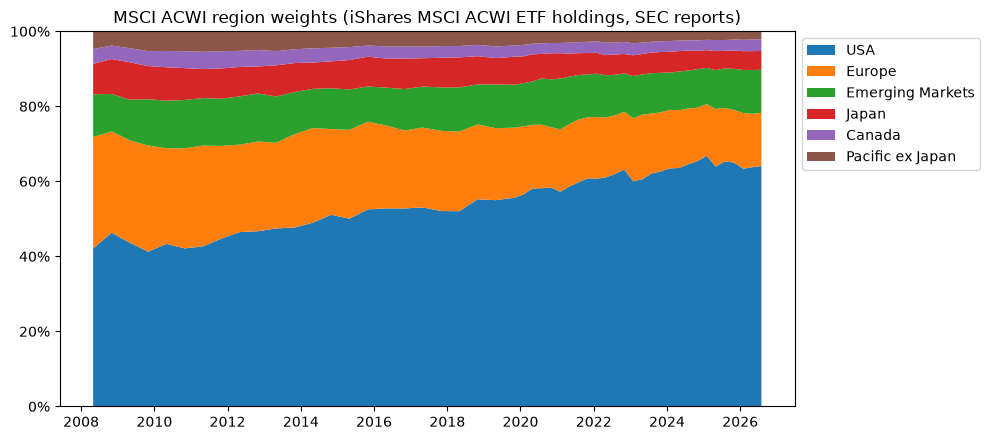

In [12]:
errors = {}
dates = acwi_weights.index[acwi_weights.index >= prices.index[0]]  # reports within the price history
for previous, current in zip(dates[:-1], dates[1:]):
    rolled, _ = acwi_weights_on(current, acwi_weights.loc[:previous], region_prices(prices))
    actual = acwi_weights.loc[current, REGIONS].astype(float)
    errors[current] = (rolled - actual).abs().sum() / 2
errors = pd.Series(errors)
print(f"Roll-forward error to the next report: average {errors.mean():.2%}, largest {errors.max():.2%} ({errors.idxmax().date()})")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.stackplot(acwi_weights.index, acwi_weights[REGIONS].T.astype(float), labels=REGIONS)
ax.set_title("MSCI ACWI region weights (iShares MSCI ACWI ETF holdings, SEC reports)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(OUTPUT / "fig_acwi_weights.png", dpi=200)
plt.show()

### Spot checks against iShares
iShares publishes the full holdings list of the ACWI ETF on its website. Old versions of this list are kept
by the Internet Archive (web.archive.org). For four dates we compare the region weights in the iShares
list with our SEC weights, rolled forward to the same date. The 2017 list still classifies companies by
their legal domicile (e.g. Bermuda), not by MSCI country, so a larger difference is expected there.

In [13]:
import gzip
import io
import requests

ISHARES_ARCHIVE = [
    "https://web.archive.org/web/20170218043220id_/https://www.ishares.com/us/products/239600/ishares-msci-acwi-etf/1467271812596.ajax?fileType=csv&fileName=ACWI_holdings&dataType=fund",
    "https://web.archive.org/web/20200506013502id_/https://www.ishares.com/us/products/239600/ishares-msci-acwi-etf/1467271812596.ajax?fileType=csv&fileName=ACWI_holdings&dataType=fund",
    "https://web.archive.org/web/20230328222332id_/https://www.ishares.com/us/products/239600/ishares-msci-acwi-etf/1467271812596.ajax?fileType=csv&fileName=ACWI_holdings&dataType=fund",
    "https://web.archive.org/web/20261118090456id_/https://www.ishares.com/us/products/239600/ishares-msci-acwi-etf/latest-holdings.csv",
]


def ishares_region_weights(url):
    """Date and region weights of an archived iShares holdings list."""
    content = requests.get(url, timeout=120).content
    if content[:2] == b"\x1f\x8b":  # some archived files are stored gzip-compressed
        content = gzip.decompress(content)
    lines = content.decode("utf-8-sig").splitlines()

    as_of_line = [line for line in lines if line.startswith("Fund Holdings as of")][0]
    as_of = pd.to_datetime(as_of_line.split(",", 1)[1].strip().strip('"'))

    header = [i for i, line in enumerate(lines) if line.startswith("Ticker,")][0]
    holdings = pd.read_csv(io.StringIO("\n".join(lines[header:])))
    holdings = holdings[holdings["Asset Class"] == "Equity"]
    country_column = "Location" if "Location" in holdings.columns else "Country"
    market_value = pd.to_numeric(holdings["Market Value"].astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")

    totals = {}
    for country, value in zip(holdings[country_column], market_value):
        if pd.notna(value):
            region = region_of_country(str(country), as_of)
            totals[region] = totals.get(region, 0.0) + value
    weights = pd.Series(totals).reindex(REGIONS).fillna(0.0)
    return as_of, weights / weights.sum()


rp = region_prices(prices)
checks = []
for url in ISHARES_ARCHIVE:
    try:
        as_of, ishares = ishares_region_weights(url)
    except Exception as error:  # the archive is an outside service; one failed download should not stop the notebook
        print("Could not load", url[:60], "-", error)
        continue
    # latest SEC report before that date, rolled forward to the same date
    report_date = acwi_weights.index[acwi_weights.index <= as_of].max()
    sec = acwi_weights.loc[report_date, REGIONS].astype(float) * rp.asof(as_of) / rp.asof(report_date)
    sec = sec / sec.sum()
    for region in REGIONS:
        checks.append({"iShares list": as_of.date(), "SEC report": report_date.date(), "Region": region,
                       "iShares": ishares[region], "SEC (rolled forward)": sec[region],
                       "Difference": sec[region] - ishares[region]})

checks = pd.DataFrame(checks)
checks.to_csv(OUTPUT / "ishares_checks.csv", index=False)
summary = checks.groupby(["iShares list", "SEC report"])["Difference"].apply(lambda d: d.abs().sum() / 2)
print("Share of the portfolio in a different region than in the iShares list:")
print(summary.map("{:.2%}".format).to_string())
checks.pivot(index="Region", columns="iShares list", values="Difference").reindex(REGIONS).round(4)

Share of the portfolio in a different region than in the iShares list:
iShares list  SEC report
2017-02-16    2016-10-31    1.87%
2020-05-04    2020-04-30    0.75%
2023-03-27    2023-01-31    0.65%
2026-11-16    2026-07-31    0.75%


iShares list,2017-02-16,2020-05-04,2023-03-27,2026-11-16
Region,,,,
USA,0.0185,-0.0064,0.0059,0.0065
Europe,-0.0104,0.0001,-0.0029,-0.0058
Emerging Markets,-0.0068,0.0058,-0.0023,-0.0008
Japan,-0.0012,-0.0011,-0.0005,0.0003
Canada,-0.0002,0.0003,0.0007,0.0007
Pacific ex Japan,0.0002,0.0013,-0.0008,-0.0008


# 3. Backtest and performance measures
Three portfolios, each starting at 1:
- **Regional Momentum:** the strategy.
- **Passive replica:** the same six ETFs at MSCI ACWI weights, without tilt. It shows how well the six ETFs
  replicate the index, so the effect of the momentum signal can be measured on its own.
- **MSCI ACWI (iShares UCITS ETF):** the benchmark.

All values are in euros.

In [14]:
result = run_all(prices, acwi_weights, rf, PARAMS)
navs = result["navs"]
returns = result["returns"]
table = result["table"]
table.to_csv(OUTPUT / "performance_table.csv")

print("Monthly returns from", returns.index[0].strftime("%b %Y"), "to", returns.index[-1].strftime("%b %Y"), f"({len(returns)} months)")

percent_columns = ["Average return p.a.", "Geometric return p.a.", "Volatility p.a.", "Alpha p.a.",
                   "Tracking error p.a.", "Max drawdown", "Turnover p.a.", "Trading costs p.a."]


def pretty(table):
    """Performance table with percentages, metrics as rows."""
    shown = table.copy()
    for column in shown.columns:
        number_format = "{:.2%}" if column in percent_columns else "{:.2f}"
        shown[column] = table[column].map(lambda x: "" if pd.isna(x) else number_format.format(x))
    return shown.T


pretty(table)

Monthly returns from Jan 2013 to Oct 2026 (166 months)


,Regional Momentum,Passive replica,MSCI ACWI (iShares UCITS ETF)
Average return p.a.,12.09%,12.31%,12.14%
Geometric return p.a.,11.92%,12.19%,11.98%
Volatility p.a.,12.44%,12.29%,12.41%
Sharpe ratio,0.92,0.95,0.93
Alpha p.a.,-0.05%,0.30%,0.00%
Alpha t-stat,-0.21,2.21,
Beta,1.00,0.99,1.00
Tracking error p.a.,0.82%,0.50%,0.00%
Information ratio,-0.06,0.35,
Max drawdown,-18.83%,-19.02%,-19.23%


**Calculation assumptions**
- All values in EUR, without currency hedging. The momentum signal uses the euro prices; converting all
  regions with the same exchange rate would not change their ranking.
- Monthly returns from month-end values (January 2013 to October 2026).
- Average return = arithmetic mean x 12; volatility = standard deviation x sqrt(12).
- Sharpe ratio = annualised average excess return over the 3-month Euribor / annualised volatility of the
  excess returns.
- Alpha and beta from the regression (r - rf) = alpha + beta x (r_ACWI - rf) + error on monthly excess
  returns. Alpha is multiplied by 12, beta is not annualised.
- Information ratio = annualised average active return (r - r_ACWI) / tracking error (annualised standard
  deviation of the active returns).
- Trading costs are deducted at each rebalancing; the initial purchase is not charged.

# 4. Figures and tables for the prospectus

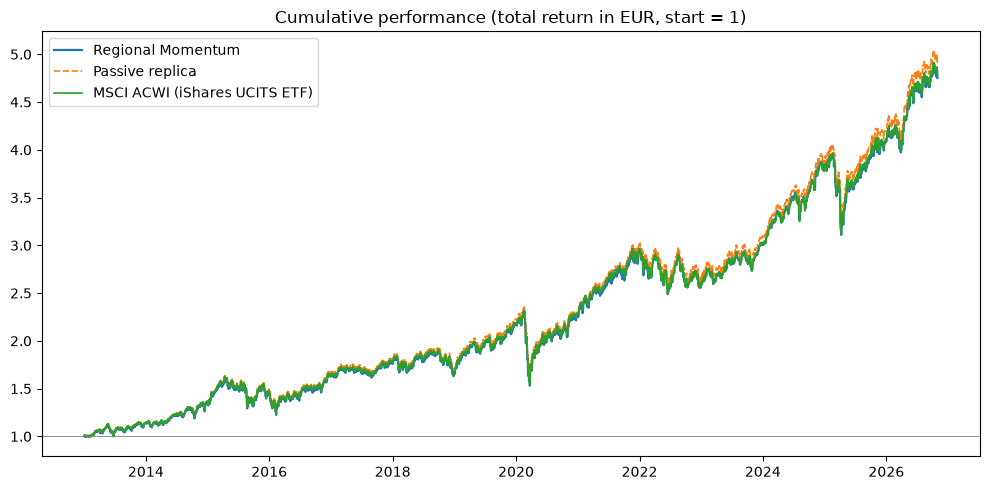

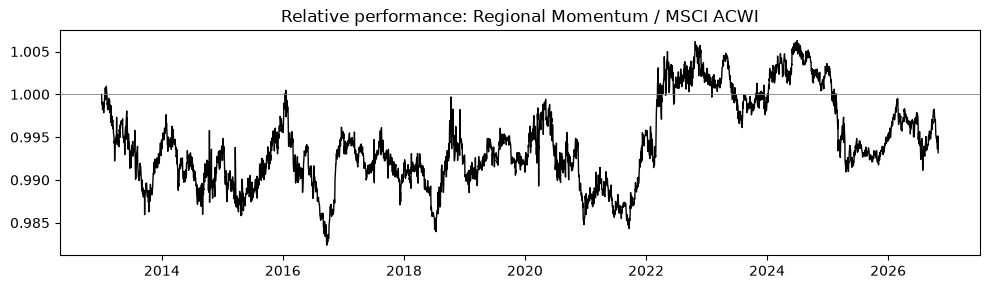

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(navs.index, navs["Regional Momentum"], label="Regional Momentum", lw=1.6)
ax.plot(navs.index, navs["Passive replica"], "--", label="Passive replica", lw=1.2)
ax.plot(navs.index, navs[BENCHMARK_NAME], label=BENCHMARK_NAME, lw=1.2)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Cumulative performance (total return in EUR, start = 1)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "fig_cumulative_performance.png", dpi=200)
plt.show()

relative = navs["Regional Momentum"] / navs[BENCHMARK_NAME]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(relative.index, relative, color="black", lw=1)
ax.axhline(1, color="grey", lw=0.6)
ax.set_title("Relative performance: Regional Momentum / MSCI ACWI")
fig.tight_layout()
fig.savefig(OUTPUT / "fig_relative_performance.png", dpi=200)
plt.show()

### Active weights over time (strategy minus passive replica)

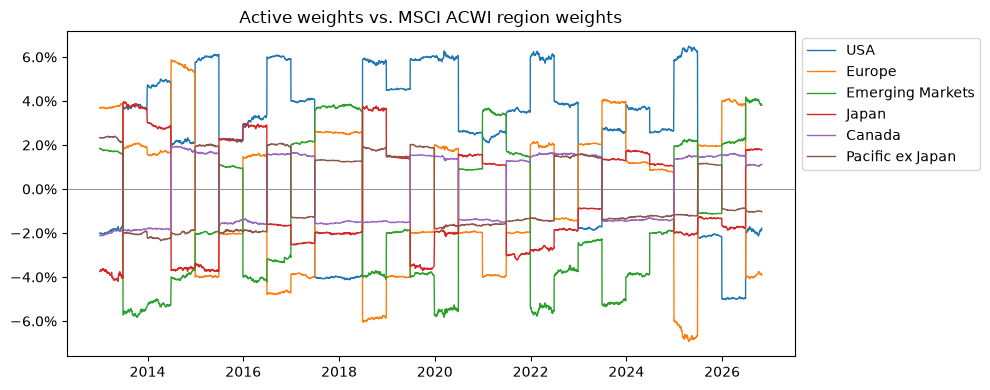

In [16]:
active_weights = result["strategy"].weights - result["passive"].weights

fig, ax = plt.subplots(figsize=(10, 4))
for region in REGIONS:
    ax.plot(active_weights.index, active_weights[region], label=region, lw=1)
ax.axhline(0, color="grey", lw=0.6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Active weights vs. MSCI ACWI region weights")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
fig.savefig(OUTPUT / "fig_active_weights.png", dpi=200)
plt.show()

### Example of the allocation rule: the latest rebalancing date

In [17]:
trades = result["strategy"].trades
trades.to_csv(OUTPUT / "rebalancing_log.csv")
last = trades.iloc[-1]

example = pd.DataFrame(index=REGIONS)
example["MSCI ACWI weight"] = [last[f"base {region}"] for region in REGIONS]
example["Momentum"] = [last[f"signal {region}"] for region in REGIONS]
example["Rank"] = example["Momentum"].rank(ascending=False).astype(int)
example["Target weight"] = [last[f"target {region}"] for region in REGIONS]
example["Active weight"] = example["Target weight"] - example["MSCI ACWI weight"]
example = example.sort_values("Rank")
example.to_csv(OUTPUT / "example_rebalancing.csv")

print("Rebalancing on", trades.index[-1].date(), "- MSCI ACWI weights from the report as of", last["anchor"].date(),
      f"- turnover {last['turnover']:.1%}")
example.round(4)

Rebalancing on 2026-06-30 - MSCI ACWI weights from the report as of 2026-04-30 - turnover 17.1%


,MSCI ACWI weight,Momentum,Rank,Target weight,Active weight
Emerging Markets,0.1208,0.4914,1,0.1626,0.0418
Japan,0.0506,0.3354,2,0.0682,0.0176
Canada,0.0300,0.3058,3,0.0405,0.0105
USA,0.6376,0.2552,4,0.6176,-0.0200
Europe,0.1412,0.2215,5,0.1012,-0.0400
Pacific ex Japan,0.0197,0.1527,6,0.0099,-0.0099


### Turnover and trading costs per rebalancing date

In [18]:
trades[["anchor", "turnover", "cost"]].round(5)

/var/folders/r3/hfblp_7j5jlbmk6__3fmcclc0000gn/T/ipykernel_22626/2532139208.py:1: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  trades[["anchor", "turnover", "cost"]].round(5)


,anchor,turnover,cost
date,,,
2013-01-02,2012-10-31,0.00000,0.00000
2013-06-28,2013-04-30,0.27701,0.00042
2013-12-30,2013-10-31,0.02162,0.00003
2014-06-30,2014-04-30,0.18421,0.00028
2014-12-30,2014-10-31,0.18046,0.00027
2015-06-30,2015-04-30,0.24248,0.00036
2015-12-30,2015-04-30,0.09886,0.00015
2016-06-30,2016-04-30,0.22112,0.00033
2016-12-30,2016-10-31,0.13152,0.00020


### Running costs (TER)
The TERs are already deducted in the fund prices, so they are part of all results above. For the
prospectus we show the weighted TER of the portfolio at the latest rebalancing date.

In [19]:
ter = FUND_FACTS["TER"]
costs = pd.DataFrame({
    "Weight": example["Target weight"],
    "TER": ter.reindex(example.index),
})
costs["Weighted TER"] = costs["Weight"] * costs["TER"]

passive_ter = sum(example["MSCI ACWI weight"][region] * ter[region] for region in REGIONS)
print(f"Weighted TER: Regional Momentum {costs['Weighted TER'].sum():.3%}, passive replica {passive_ter:.3%}, "
      f"benchmark fund {ter['Benchmark']:.2%}")
print(f"Trading costs from rebalancing: {table.loc['Regional Momentum', 'Trading costs p.a.']:.3%} p.a.")
costs.to_csv(OUTPUT / "weighted_ter.csv")
costs.round(5)

Weighted TER: Regional Momentum 0.114%, passive replica 0.108%, benchmark fund 0.20%
Trading costs from rebalancing: 0.043% p.a.


,Weight,TER,Weighted TER
Emerging Markets,0.16260,0.0018,0.00029
Japan,0.06824,0.0012,0.00008
Canada,0.04049,0.0048,0.00019
USA,0.61757,0.0007,0.00043
Europe,0.10122,0.0012,0.00012
Pacific ex Japan,0.00987,0.0020,0.00002


### Calendar-year returns (EUR)

In [20]:
year_end_values = navs.resample("YE").last()
annual = year_end_values.pct_change()
annual.iloc[0] = year_end_values.iloc[0] / navs.iloc[0] - 1  # first year from the start date
annual.index = annual.index.year
annual["Active (vs. MSCI ACWI)"] = annual["Regional Momentum"] - annual[BENCHMARK_NAME]
annual.to_csv(OUTPUT / "annual_returns.csv")

years_ahead = (annual["Active (vs. MSCI ACWI)"] > 0).sum()
print(f"The strategy beat the MSCI ACWI in {years_ahead} of {len(annual)} calendar years")
annual.round(4)

The strategy beat the MSCI ACWI in 5 of 14 calendar years


,Regional Momentum,Passive replica,MSCI ACWI (iShares UCITS ETF),Active (vs. MSCI ACWI)
Date,,,,
2013,0.1371,0.1447,0.1432,-0.0061
2014,0.1894,0.1925,0.1902,-0.0008
2015,0.0853,0.0913,0.0831,0.0022
2016,0.1076,0.1127,0.1088,-0.0013
2017,0.0865,0.0898,0.0914,-0.0049
2018,-0.0575,-0.0556,-0.0597,0.0022
2019,0.3005,0.3011,0.3014,-0.0010
2020,0.0450,0.0415,0.0494,-0.0044
2021,0.3018,0.3016,0.2913,0.0104


# 5. Risk class (SRI)
The summary risk indicator of the EU PRIIPs rules, on a scale from 1 (lowest) to 7 (highest), as shown in
the key information document of every fund sold to retail investors in Portugal. It uses daily values in
EUR over the last 5 years of the sample and a recommended holding period of 7 years (our clients'
horizon). The class limits for the VaR-equivalent volatility are 0.5%, 5%, 12%, 20%, 30% and 80%.

In [21]:
risk = pd.DataFrame({name: risk_class(navs[name], PARAMS.end, holding_years=7) for name in navs.columns}).T
risk.to_csv(OUTPUT / "risk_class.csv")
risk["SRI (1-7)"] = risk["SRI (1-7)"].astype(int)
risk.round(4)

,"Volatility p.a. (daily, 5y)",Skewness,Excess kurtosis,VaR 97.5% (holding period),VaR-equivalent volatility,SRI (1-7)
Regional Momentum,0.1408,-0.6246,4.0003,-0.8022,0.1413,4
Passive replica,0.1386,-0.6274,4.0357,-0.7885,0.1390,4
MSCI ACWI (iShares UCITS ETF),0.1409,-0.5967,4.0049,-0.8029,0.1414,4


# 6. Sensitivity analysis
Each row changes one assumption of the base case and keeps everything else as it is.

In [22]:
grid = {
    "rebalance": ["Q", "S", "A"],
    "lookback_months": [6, 12],
    "tilt_pp": [0.0, 3.0, 6.0, 10.0],
    "cost_bps": [0.0, 15.0, 50.0],
}
sens = sensitivity(prices, acwi_weights, rf, PARAMS, grid)
sens.to_csv(OUTPUT / "sensitivity.csv")
sens.round(4)

Average return p.a.  Volatility p.a.  Sharpe ratio  \
parameter       value                                                       
rebalance       Q                   0.1223           0.1242        0.9324   
                S                   0.1209           0.1244        0.9192   
                A                   0.1216           0.1247        0.9224   
lookback_months 6                   0.1227           0.1237        0.9393   
                12                  0.1209           0.1244        0.9192   
tilt_pp         0.0                 0.1231           0.1229        0.9486   
                3.0                 0.1215           0.1236        0.9298   
                6                   0.1209           0.1244        0.9192   
                10.0                0.1207           0.1249        0.9141   
cost_bps        0.0                 0.1213           0.1244        0.9229   
                15.0                0.1209           0.1244        0.9192   
                50.0                0.1199           0.1245        0.9106   

                       Alpha p.a.    Beta  Information ratio  Turnover p.a.  
parameter       value                                                        
rebalance       Q          0.0011  0.9984             0.1207         0.3771  
                S         -0.0005  1.0000            -0.0574         0.2850  
                A         -0.0000  1.0023             0.0242         0.2081  
lookback_months 6          0.0020  0.9942             0.1682         0.3697  
                12        -0.0005  1.0000            -0.0574         0.2850  
tilt_pp         0.0        0.0030  0.9892             0.3483         0.0208  
                3.0        0.0007  0.9946             0.0178         0.1829  
                6         -0.0005  1.0000            -0.0574         0.2850  
                10.0      -0.0010  1.0032            -0.0680         0.3515  
cost_bps        0.0       -0.0000  0.9998            -0.0052         0.2850  
                15.0      -0.0005  1.0000            -0.0574         0.2850  
                50.0      -0.0015  1.0007            -0.1765         0.2850

# 7. Check against the app
The Streamlit app imports the same functions from `regional_momentum/core.py`. With its default settings
it must show the numbers below.

In [23]:
main_numbers = table[["Average return p.a.", "Volatility p.a.", "Sharpe ratio", "Alpha p.a.", "Beta", "Information ratio"]]
(OUTPUT / "default_metrics.json").write_text(json.dumps(main_numbers.round(6).to_dict(orient="index"), indent=2))
main_numbers.round(4)

,Average return p.a.,Volatility p.a.,Sharpe ratio,Alpha p.a.,Beta,Information ratio
Regional Momentum,0.1209,0.1244,0.9192,-0.0005,1.0000,-0.0574
Passive replica,0.1231,0.1229,0.9486,0.0030,0.9892,0.3483
MSCI ACWI (iShares UCITS ETF),0.1214,0.1241,0.9250,0.0000,1.0000,NaN
